# Pathology Annotations

**C-Stroke · case HB02CV · reference notebook 2 of 4**

The C-Stroke slides come with annotations of the pathology they show. These are region polygons drawn on the whole-slide images:

* **IHC slides:** regions of the stained marker, graded where the marker has several classes. GFAP slides, for example, are divided into *sparse*, *moderately dense* and *dense astrocytes*; fibrinogen slides mark *blood–brain barrier disruption*.
* **H&E slides:** the **infarcted region**.

These annotations are what the platform's feature overlays display. This notebook shows how to use them in code:

1. Load the annotation of a slide and inspect its classes and polygons.
2. Measure polygons, filter them by class or size, and combine them.
3. Turn annotations into label masks for image analysis and machine learning.
4. Use the H&E infarct as a spatial reference on any other slide of the same block.
5. Compare markers annotated on neighbouring sections.
6. Check annotations against the DAB stain itself.
7. Export annotations as GeoJSON and masks.

The annotation classes are provided in `pathology_utils.py` (`SectionAnnotation`, `AnnotationSeries`), and images come from `slide_utils.py` (see `slide_catalog_and_images.ipynb`).

**Runtime:** a few minutes on a CPU.

## 1. Setup

The notebook uses the helper modules of this repository. In a local clone they are found automatically. On Google Colab, Kaggle or any other fresh environment, the cell below clones the repository first. All data are read from the C-Stroke platform at `https://c-stroke.humanbrain.in` and cached under `~/.cache/cstroke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/24f2007780/stroke_utils.git"

# Use the local repository (this notebook's parent folder) if present; otherwise clone it.
root = next((p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "stroke_utils")
             if (p / "slide_utils.py").exists()), None)
if root is None:
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    root = Path.cwd() / "stroke_utils"
sys.path.insert(0, str(root))
print("Helper modules from", root)

Helper modules from /home/antareep/workspace/stroke_notebook/stroke_utils


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import display_utils as du
from pathology_utils import SectionAnnotation, signed_distance_mm, stain_separation
from slide_utils import MARKERS, STAINS, Region, SlideCatalog, SlideHelper, tissue_mask

du.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

catalog = SlideCatalog()

# Worked example: a GFAP slide of block 313 whose set also contains an infarct-annotated H&E section.
BLOCK, GFAP_SECTION = 313, 1421

# Section 7: a location of block 314 where six markers are annotated within 0.6 mm of each other.
NEIGHBOUR_BLOCK, NEIGHBOUR_SECTION, MAX_OFFSET_UM = 314, 480, 600

## 2. Which slides are annotated

Annotations exist for most IHC slides and for the H&E slides of the three left-hemisphere blocks (313, 314, 315). `catalog.find(..., annotated=True)` lists them. Each IHC marker has its own set of classes, ordered from mildest to most severe. Their position in that order is the polygon's **grade**.

In [3]:
annotated = catalog.find(annotated=True)
coverage = (annotated.assign(type=annotated.annotation_type.fillna("?"))
            .pivot_table(index="type", columns="block", values="section", aggfunc="count", fill_value=0))
coverage.index = [("Infarct (H&E)" if t == "HE" else f"{t}: {MARKERS[t]['target']}") for t in coverage.index]
coverage

block,217,218,313,314,315
APP: Axonal injury,6,8,10,3,2
CD34: Microvessels,21,25,11,6,6
CD68: Microglia and macrophages,13,19,16,26,9
FIB: Fibrinogen leakage (blood-brain barrier disruption),13,19,23,16,12
GAP43: Axonal regrowth,11,1,12,2,2
GFAP: Reactive astrocytes,9,21,20,15,11
Infarct (H&E),0,0,39,46,29
HIF1a: Hypoxic cells,18,13,13,27,2


In [4]:
classes = pd.DataFrame([{"marker": m, "grade": g + 1, "class": c}
                        for m, v in MARKERS.items() for g, c in enumerate(v["classes"])])
classes.pivot(index="marker", columns="grade", values="class").fillna("")

grade,1,2,3
marker,,,
APP,axonal injury,,
CD34,sparse microvessels,moderately dense microvessels,dense microvessels
CD68,moderately dense CD68+ immune cells,dense CD68+ immune cells,
FIB,blood brain barrier disruption,,
GAP43,axonal regrowth,,
GFAP,sparse astrocytes,moderately dense astrocytes,dense astrocytes
HE,Infarcted region,,
HIF1a,moderately dense HIF1α+ cells,dense HIF1α+ cells,


## 3. The annotation of one slide

`SlideHelper.get_annotation(section)` returns a `SectionAnnotation`. Its `records` are dicts with the class `label`, the `grade` and the polygon `geometry`, a shapely geometry in canvas pixels (the same coordinates as the images). `summary()` aggregates the polygons per class; `table()` measures each polygon.

In [5]:
gfap = SlideHelper(BLOCK, "IHC", downsample=6, catalog=catalog)
annotation = gfap.get_annotation(GFAP_SECTION)
print(annotation)
print("first record:", {k: (v if k != "geometry" else v.geom_type) for k, v in annotation.records[0].items()})
annotation.summary()

SectionAnnotation(GFAP, block 313, section 1421, 236 polygons, 1791.1 mm2)
first record: {'label': 'dense astrocytes', 'grade': 3, 'geometry': 'Polygon'}


,grade,class,polygons,total_mm2,median_mm2
0,1,sparse astrocytes,128,1202.494,1.170
1,2,moderately dense astrocytes,78,501.458,0.855
2,3,dense astrocytes,30,87.131,0.478


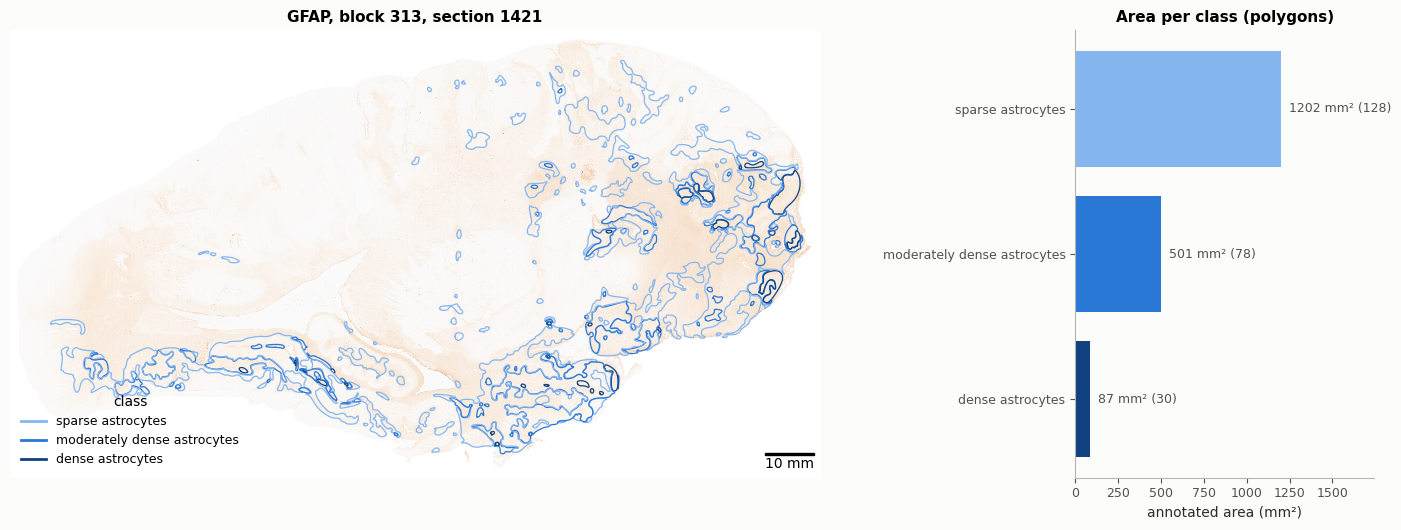

In [6]:
image, region = gfap.get_sectionimage(GFAP_SECTION)
summary = annotation.summary()

fig, (ax, axb) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [3.2, 1]})
du.show_image(ax, image, region, f"GFAP, block {BLOCK}, section {GFAP_SECTION}", bar_mm=10)
du.draw_annotation(ax, annotation, region, linewidth=0.9)
ax.legend(handles=[Line2D([], [], color=du.GRADE_COLORS[g], lw=2, label=c)
                   for g, c in enumerate(annotation.classes, start=1)], loc="lower left", title="class")
axb.barh(summary["class"], summary.total_mm2, color=[du.GRADE_COLORS[g] for g in summary.grade])
for y, (n, a) in enumerate(zip(summary.polygons, summary.total_mm2)):
    axb.text(a, y, f"  {a:.0f} mm² ({n})", va="center", fontsize=9, color="#52514e")
axb.invert_yaxis()
axb.set_xlabel("annotated area (mm²)")
axb.set_title("Area per class (polygons)")
axb.set_xlim(0, summary.total_mm2.max() * 1.45)
plt.tight_layout()
plt.show()

## 4. Measuring and selecting polygons

### 4.1 Polygon measurements

`table()` returns one row per polygon: area, perimeter, a representative point inside it (`x`, `y`, in canvas pixels), compactness (1 for a disc, lower for elongated or ragged shapes) and the number of holes. The distributions show that the classes differ in shape as well as size. Dense regions here are smaller and more compact than sparse ones.

,polygon,class,grade,area_mm2,perimeter_mm,x,y,compactness,holes
0,0,dense astrocytes,3,2.953,9.109,157315.672,82624.316,0.447,0
1,1,sparse astrocytes,1,0.925,3.480,149927.919,81898.201,0.960,0
2,2,sparse astrocytes,1,2.251,7.066,155961.290,76673.562,0.566,0
3,3,sparse astrocytes,1,1.283,4.576,150385.754,71128.759,0.770,0
4,4,moderately dense astrocytes,2,0.345,2.103,156434.185,80511.951,0.981,0


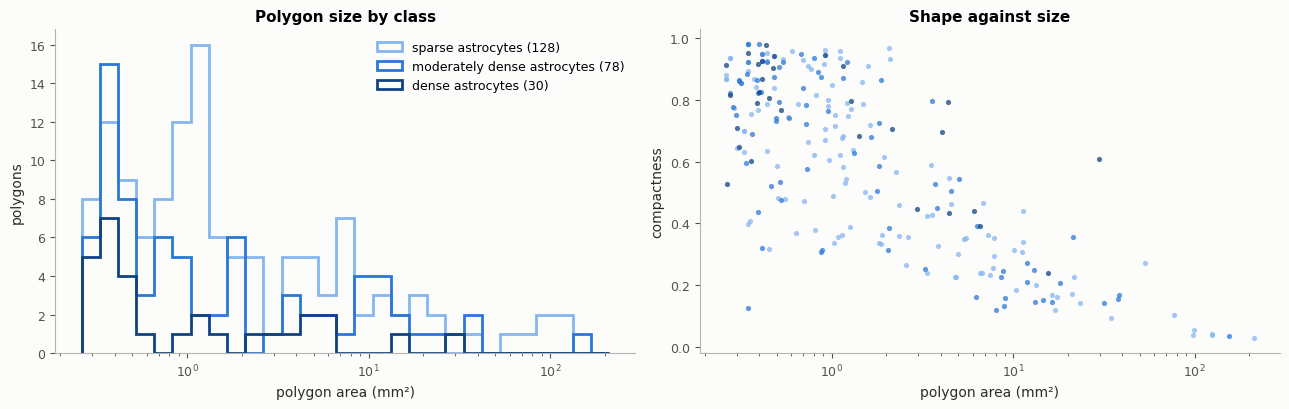

In [7]:
polygons = annotation.table()
display(polygons.head())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.logspace(np.log10(polygons.area_mm2.min()), np.log10(polygons.area_mm2.max()), 30)
for g, c in enumerate(annotation.classes, start=1):
    sub = polygons[polygons.grade == g]
    ax1.hist(sub.area_mm2, bins=bins, histtype="step", lw=2, color=du.GRADE_COLORS[g], label=f"{c} ({len(sub)})")
    ax2.scatter(sub.area_mm2, sub.compactness, s=14, color=du.GRADE_COLORS[g], alpha=0.75, lw=0, label=c)
ax1.set_xscale("log"); ax1.set_xlabel("polygon area (mm²)"); ax1.set_ylabel("polygons"); ax1.legend()
ax1.set_title("Polygon size by class")
ax2.set_xscale("log"); ax2.set_xlabel("polygon area (mm²)"); ax2.set_ylabel("compactness")
ax2.set_title("Shape against size")
plt.tight_layout()
plt.show()

### 4.2 Filtering and combining

`filter(labels=..., min_grade=..., min_area_mm2=...)` returns a new annotation with the selected polygons only. `union(min_grade)` merges them into one geometry. Overlaps are counted once, so `area_mm2(min_grade)` is the true area covered. `by_class()` gives one merged geometry per class.

all polygons: 236, covering 1791.1 mm2
moderately dense or dense: 588.6 mm2
dense only: 30 polygons, 87.1 mm2
polygons of at least 1 mm2: 124


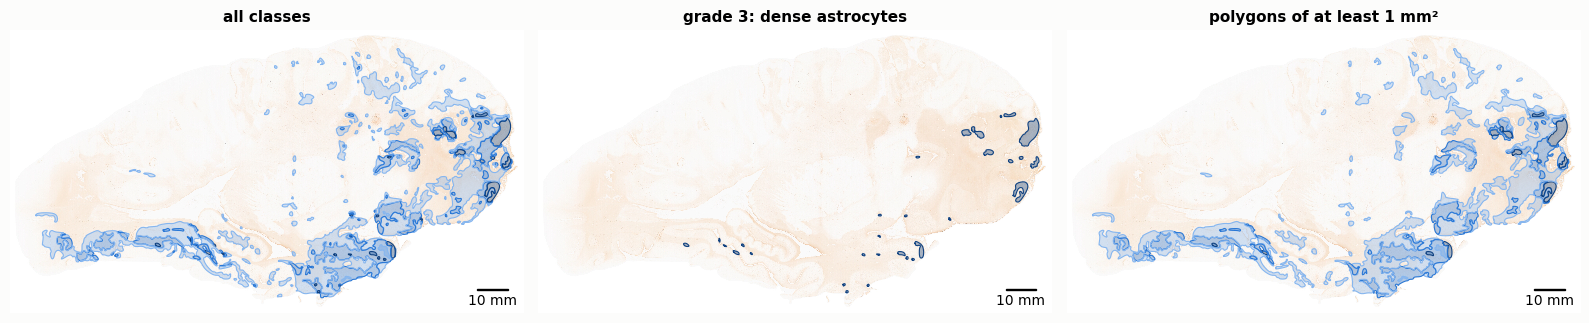

In [8]:
dense = annotation.filter(min_grade=3)
large = annotation.filter(min_area_mm2=1.0)
print(f"all polygons: {len(annotation)}, covering {annotation.area_mm2():.1f} mm2")
print(f"moderately dense or dense: {annotation.area_mm2(min_grade=2):.1f} mm2")
print(f"dense only: {len(dense)} polygons, {dense.area_mm2():.1f} mm2")
print(f"polygons of at least 1 mm2: {len(large)}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (title, ann) in zip(axes, [("all classes", annotation), ("grade 3: dense astrocytes", dense),
                                   ("polygons of at least 1 mm²", large)]):
    du.show_image(ax, image, region, title, bar_mm=10)
    du.draw_annotation(ax, ann, region, linewidth=0.8, fill_alpha=0.35)
plt.tight_layout()
plt.show()

## 5. Label masks

Most image-analysis tools expect a label image rather than polygons. `to_mask(region, value)` rasterises the annotation onto the pixel grid of any `Region`, for example the region of an image you have just read. With `value="grade"` every pixel holds the highest grade that covers it (0 = not annotated). With `value="binary"` it holds 1 inside any polygon.

Because masks follow the region, the same call gives a mask for a whole section at low resolution, or for a single field at full resolution.

mask (1450, 2626) uint8 | pixels per grade: {0: 3358146, 1: 300839, 2: 126403, 3: 22312}


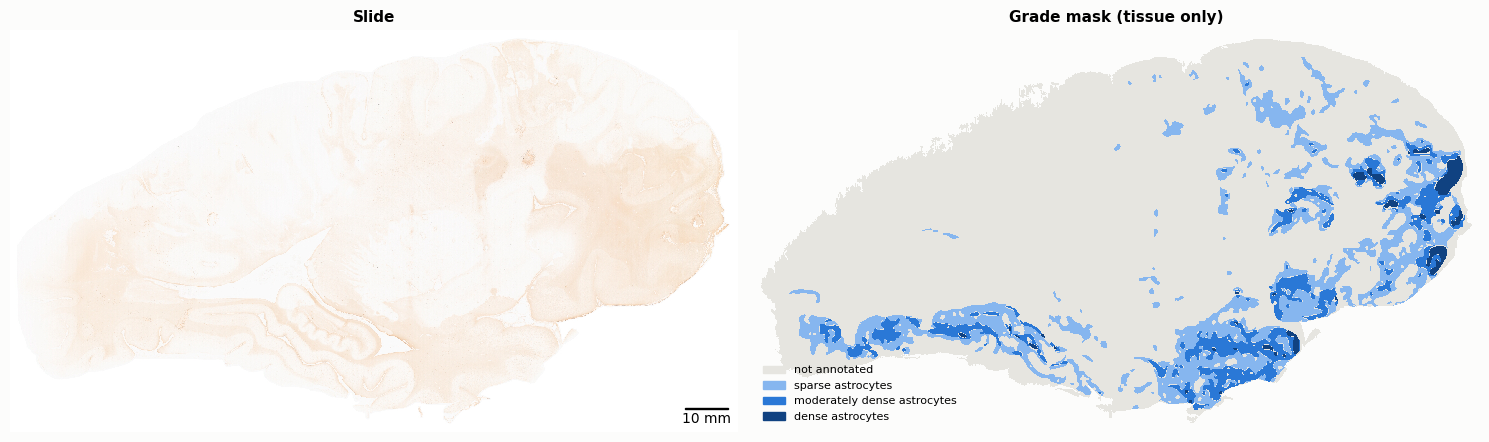

In [9]:
grade_mask = annotation.to_mask(region, value="grade")
print("mask", grade_mask.shape, grade_mask.dtype, "| pixels per grade:", dict(zip(*np.unique(grade_mask, return_counts=True))))

cmap = plt.matplotlib.colors.ListedColormap([du.GRADE_COLORS[g] for g in range(4)])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
du.show_image(axes[0], image, region, "Slide", bar_mm=10)
axes[1].imshow(np.where(tissue_mask(image), grade_mask, np.nan), cmap=cmap, vmin=-0.5, vmax=3.5)
axes[1].set_title("Grade mask (tissue only)")
axes[1].axis("off")
axes[1].legend(handles=[Patch(color=du.GRADE_COLORS[g], label=(["not annotated"] + annotation.classes)[g])
                        for g in range(4)], loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### 5.1 Labelled tiles

Combining `to_mask` with `SlideHelper.iter_tiles` gives labelled training data. Each tile carries the share of each grade inside it, measured by rasterising the annotation onto that tile. Below, 896 µm tiles at 4 µm per pixel from a 6 mm square of the section, each labelled with its dominant grade.

,x0,y0,dominant_grade,share_grade_0,share_grade_1,share_grade_2,share_grade_3
0,160521.545,85442.814,0,0.998,0.000,0.002,0.000
1,161417.545,85442.814,0,0.710,0.000,0.220,0.070
2,162313.545,85442.814,3,0.000,0.000,0.000,1.000
3,163209.545,85442.814,3,0.000,0.000,0.000,1.000
4,164105.545,85442.814,3,0.000,0.000,0.000,1.000


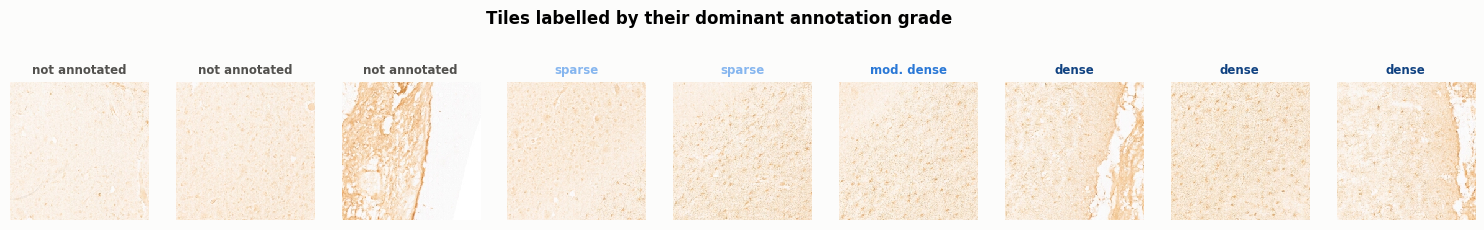

In [10]:
x0, y0, w, h = gfap.get_tissue_bbox(GFAP_SECTION)
dense_point = dense.table().sort_values("area_mm2").iloc[-1]          # inside the largest dense polygon
window = (dense_point.x - 3000, dense_point.y - 3000, 6000, 6000)     # 6 x 6 mm of canvas

rows = []
for tile, tx, ty in gfap.iter_tiles(GFAP_SECTION, tile_px=224, downsample=2, min_tissue=0.5, bbox=window):
    mask = annotation.to_mask(Region(tx, ty, 4.0, tile.shape[:2]), value="grade")
    shares = np.bincount(mask.ravel(), minlength=4) / mask.size
    rows.append({"x0": tx, "y0": ty, "tile": tile, "dominant_grade": int(shares.argmax()),
                 **{f"share_grade_{g}": shares[g] for g in range(4)}})
labelled = pd.DataFrame(rows)
display(labelled.drop(columns="tile").head())

order = labelled.sort_values(["dominant_grade", "share_grade_3"], ascending=[True, True])
picks = pd.concat([order[order.dominant_grade == g].head(3) for g in sorted(order.dominant_grade.unique())])
fig, axes = plt.subplots(1, len(picks), figsize=(2.1 * len(picks), 2.6))
for ax, (_, t) in zip(np.atleast_1d(axes), picks.iterrows()):
    ax.imshow(t.tile)
    label = (["not annotated"] + annotation.classes)[t.dominant_grade]
    ax.set_title(label.replace(" astrocytes", "").replace("moderately", "mod."), fontsize=8.5,
                 color=du.GRADE_COLORS[max(t.dominant_grade, 1)] if t.dominant_grade else "#52514e")
    ax.axis("off")
plt.suptitle("Tiles labelled by their dominant annotation grade", fontweight="bold", y=1.04)
plt.show()

## 6. The infarct as a spatial reference

The infarct is outlined on H&E slides, but all slides of a block share one canvas, so the outline can be placed on any other slide. `catalog.neighbours` finds the nearest infarct-annotated H&E section. `distance_map(region)` then gives every pixel's signed distance to the infarct border, negative inside, in millimetres. With it, any measurement on any stain can be expressed relative to the lesion.

nearest annotated H&E: section 1424 (60 um away) -> SectionAnnotation(HE, block 313, section 1424, 8 polygons, 1981.7 mm2)


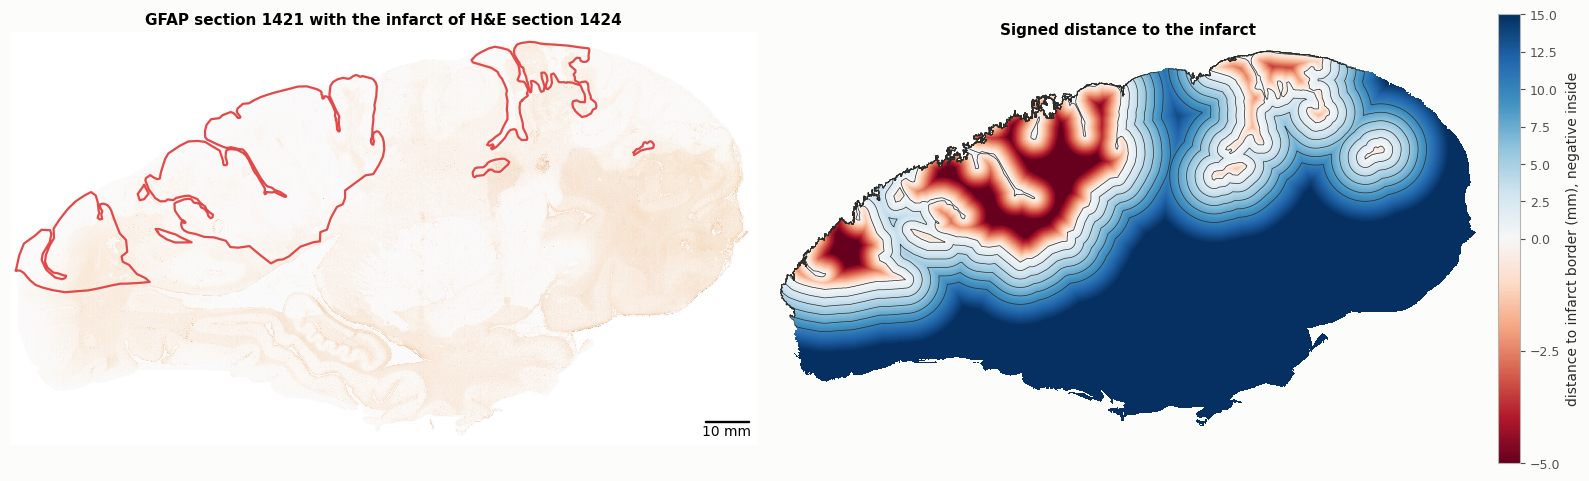

In [11]:
he_row = catalog.nearest(BLOCK, GFAP_SECTION, "HE", annotated=True)
infarct = SlideHelper(BLOCK, "HE", catalog=catalog).get_annotation(he_row.section)
print(f"nearest annotated H&E: section {he_row.section} ({abs(he_row.gap_sections) * 20} um away) -> {infarct}")

distance = infarct.distance_map(region)
tissue = tissue_mask(image)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
du.show_image(axes[0], image, region, f"GFAP section {GFAP_SECTION} with the infarct of H&E section {he_row.section}",
              bar_mm=10)
du.draw_annotation(axes[0], infarct, region, colors={1: du.INFARCT_COLOR}, linewidth=1.6)
h = axes[1].imshow(np.where(tissue, distance, np.nan), cmap="RdBu",
                   norm=plt.matplotlib.colors.TwoSlopeNorm(vmin=-5, vcenter=0, vmax=15))
axes[1].contour(np.where(tissue, distance, 99), levels=[0, 2, 4, 6, 8, 10], colors="#2b2b29", linewidths=0.5)
plt.colorbar(h, ax=axes[1], fraction=0.03, pad=0.02, label="distance to infarct border (mm), negative inside")
axes[1].set_title("Signed distance to the infarct")
axes[1].axis("off")
plt.tight_layout()
plt.show()

With the distance map, the annotated share of tissue can be read off in distance bands. On this slide, GFAP annotations are almost absent inside the infarct and become more frequent with distance outside it. `lesion_across_sections.ipynb` builds the same profile over every slide and marker of the dataset.

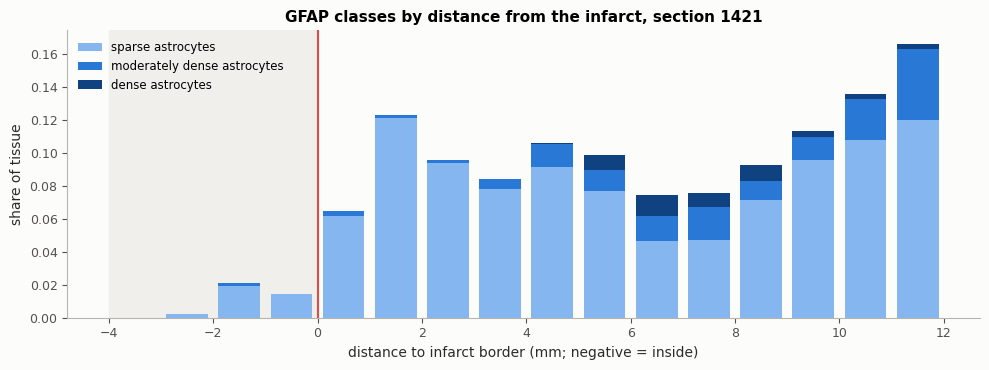

In [12]:
edges = np.arange(-4, 12.1, 1.0)
band = np.digitize(distance, edges) - 1
profile = pd.DataFrame([{"distance_mm": (edges[b] + edges[b + 1]) / 2,
                         "tissue_mm2": (tissue & (band == b)).sum() * region.mpp ** 2 / 1e6,
                         **{c: (grade_mask[tissue & (band == b)] == g).mean() for g, c in enumerate(annotation.classes, 1)}}
                        for b in range(len(edges) - 1) if (tissue & (band == b)).sum() > 50])

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(profile))
for g, c in enumerate(annotation.classes, start=1):
    ax.bar(profile.distance_mm, profile[c], bottom=bottom, width=0.8, color=du.GRADE_COLORS[g], label=c)
    bottom += profile[c].to_numpy()
ax.axvspan(edges[0], 0, color="#f0efec", zorder=0)
ax.axvline(0, color=du.INFARCT_COLOR, lw=1.5)
ax.set_xlabel("distance to infarct border (mm; negative = inside)")
ax.set_ylabel("share of tissue")
ax.set_title(f"GFAP classes by distance from the infarct, section {GFAP_SECTION}")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

## 7. Markers on neighbouring sections

Each IHC slide shows one marker, but the markers were stained on interleaved sections. Placing the annotations of neighbouring IHC sections on one canvas shows where different processes coincide.

The example below uses a location in block 314 (`NEIGHBOUR_BLOCK`, `NEIGHBOUR_SECTION`). It takes the nearest annotated slide of every marker within `MAX_OFFSET_UM` and draws the infarct as reference. The pairwise overlap (Jaccard index of the annotated areas) is then computed. Annotated sections of different markers are often millimetres apart, so it is worth checking the offsets before comparing them.

In [13]:
neighbour_annotations = {}
ihc_helper = SlideHelper(NEIGHBOUR_BLOCK, "IHC", catalog=catalog)
for marker in [m for m in MARKERS if m != "HE"]:
    try:
        row = catalog.nearest(NEIGHBOUR_BLOCK, NEIGHBOUR_SECTION, "IHC", marker=marker, annotated=True)
    except KeyError:
        continue
    if abs(row.gap_sections) * 20 <= MAX_OFFSET_UM:
        neighbour_annotations[marker] = (row.section, row.gap_sections, ihc_helper.get_annotation(row.section))
pd.DataFrame([{"marker": m, "section": s, "offset_um": g * 20, "polygons": len(a), "area_mm2": a.area_mm2()}
              for m, (s, g, a) in neighbour_annotations.items()])

,marker,section,offset_um,polygons,area_mm2
0,CD68,455,-500,62,4004.600
1,CD34,503,460,38,1762.366
2,HIF1a,479,-20,62,1587.450
3,FIB,491,220,8,522.114
4,APP,485,100,20,135.573
5,GAP43,467,-260,12,40.829


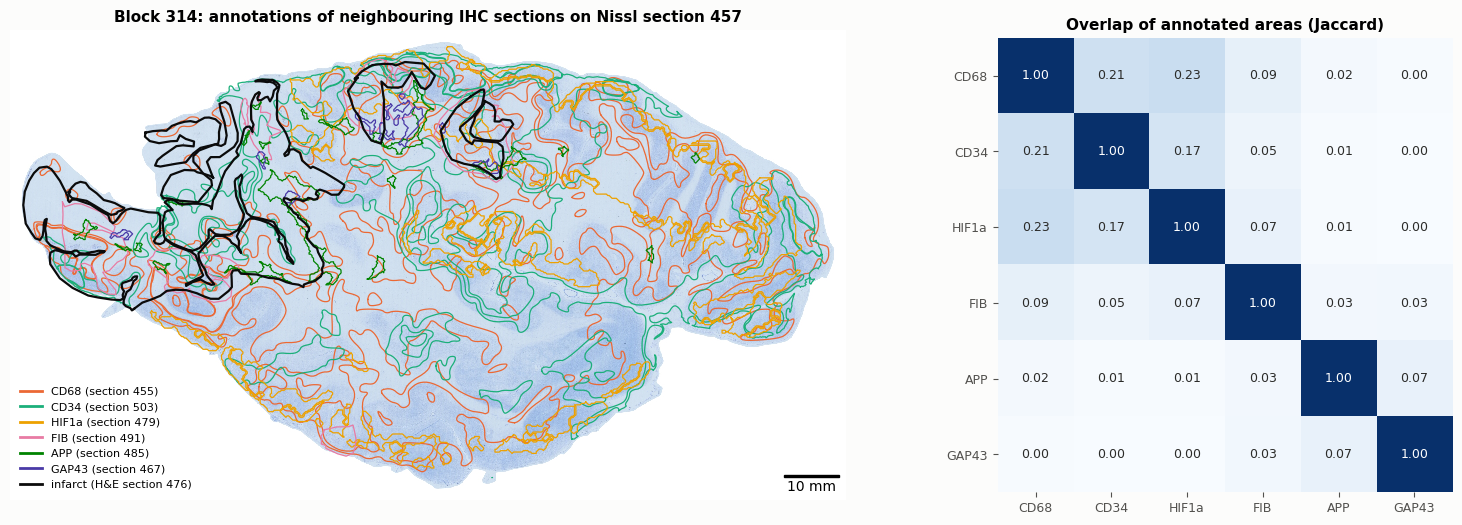

In [14]:
markers = list(neighbour_annotations)
unions = {m: a.union() for m, (_, _, a) in neighbour_annotations.items()}
jaccard = pd.DataFrame([[unions[a].intersection(unions[b]).area / max(unions[a].union(unions[b]).area, 1)
                         for b in markers] for a in markers], index=markers, columns=markers)

fig, (ax, axm) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [2.4, 1]})
nissl_row = catalog.nearest(NEIGHBOUR_BLOCK, NEIGHBOUR_SECTION, "N")
nissl_img, nissl_reg = SlideHelper(NEIGHBOUR_BLOCK, "N", catalog=catalog).get_sectionimage(nissl_row.section)
he_near = catalog.nearest(NEIGHBOUR_BLOCK, NEIGHBOUR_SECTION, "HE", annotated=True)
infarct_near = SlideHelper(NEIGHBOUR_BLOCK, "HE", catalog=catalog).get_annotation(he_near.section)
du.show_image(ax, nissl_img, nissl_reg, f"Block {NEIGHBOUR_BLOCK}: annotations of neighbouring IHC sections on Nissl "
              f"section {nissl_row.section}", bar_mm=10)
for m, (_, _, a) in neighbour_annotations.items():
    du.draw_annotation(ax, a, nissl_reg, colors={g: du.MARKER_COLORS[m] for g in range(1, 4)}, linewidth=0.9)
du.draw_annotation(ax, infarct_near, nissl_reg, colors={1: "#0b0b0b"}, linewidth=1.6)
ax.legend(handles=[Line2D([], [], color=du.MARKER_COLORS[m], lw=2, label=f"{m} (section {s})")
                   for m, (s, _, _) in neighbour_annotations.items()]
          + [Line2D([], [], color="#0b0b0b", lw=2, label=f"infarct (H&E section {he_near.section})")],
          loc="lower left", fontsize=8)
axm.imshow(jaccard.values, cmap="Blues", vmin=0, vmax=1)
axm.set_xticks(range(len(markers)), markers); axm.set_yticks(range(len(markers)), markers)
for (r, c), v in np.ndenumerate(jaccard.values):
    axm.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else "#2b2b29")
axm.set_title("Overlap of annotated areas (Jaccard)")
axm.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

Overlaps are computed between different sections, here up to 0.6 mm apart. They describe how regions coincide, not whether the same cells express both markers.

## 8. Annotations and the stain

On IHC slides the marker is detected with DAB, a brown chromogen. `stain_separation(rgb)` separates an image into haematoxylin and DAB optical densities by colour deconvolution. The C-Stroke IHC slides carry no counterstain, so almost all signal falls into the DAB channel. Comparing DAB inside and outside the annotation is a quick way to see how closely an annotation follows the stain. The comparison is close for diffusely stained markers such as fibrinogen or HIF1α, and looser for markers graded by cell morphology and density, such as GFAP.

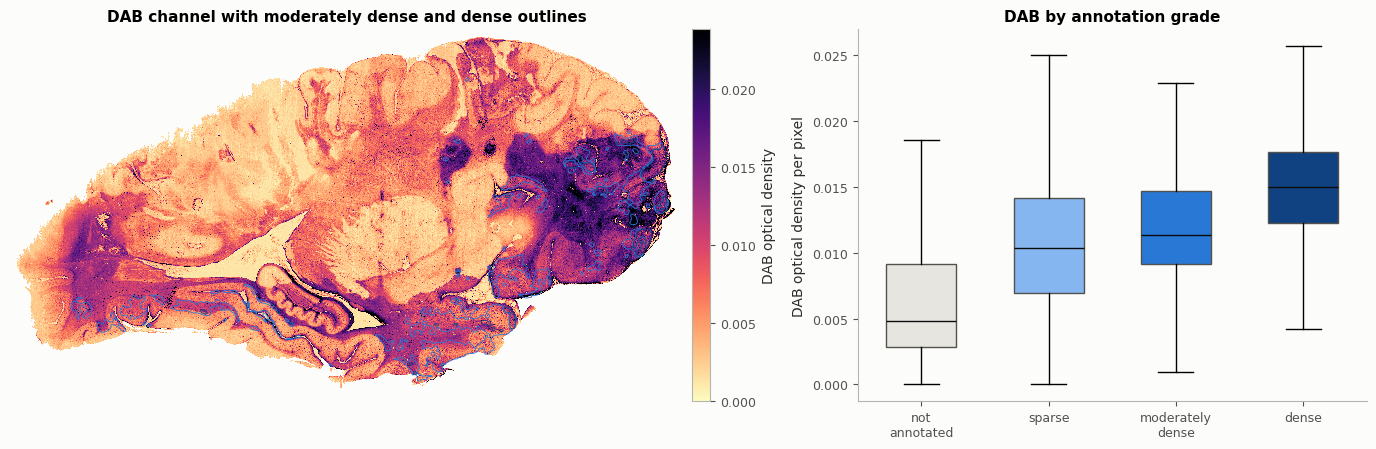

In [15]:
dab_image, dab_region = gfap.get_sectionimage(GFAP_SECTION, downsample=4)        # 16 um per pixel
_, dab = stain_separation(dab_image)
dab_tissue = tissue_mask(dab_image)
dab_grades = annotation.to_mask(dab_region, value="grade")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
h = ax1.imshow(np.where(dab_tissue, dab, np.nan), cmap="magma_r", vmin=0, vmax=np.nanpercentile(dab[dab_tissue], 99))
du.draw_annotation(ax1, annotation.filter(min_grade=2), dab_region, colors={2: "#2a78d6", 3: "#104281"}, linewidth=0.6)
plt.colorbar(h, ax=ax1, fraction=0.025, pad=0.01, label="DAB optical density")
ax1.set_title("DAB channel with moderately dense and dense outlines")
ax1.axis("off")
data = [dab[dab_tissue & (dab_grades == g)] for g in range(4)]
bp = ax2.boxplot(data, widths=0.55, showfliers=False, patch_artist=True, medianprops={"color": "#0b0b0b"})
for patch, g in zip(bp["boxes"], range(4)):
    patch.set_facecolor(du.GRADE_COLORS[g]); patch.set_edgecolor("#52514e")
ax2.set_xticks(range(1, 5), ["not\nannotated"] + [c.replace(" astrocytes", "").replace(" ", "\n", 1) for c in annotation.classes])
ax2.set_ylabel("DAB optical density per pixel")
ax2.set_title("DAB by annotation grade")
plt.tight_layout()
plt.show()

## 9. Export

* `to_geojson(path)` writes a GeoJSON FeatureCollection with class, grade, block and section as properties. Coordinates are full-resolution pixels with y pointing down, which matches the slide images and tools such as QuPath.
* Masks from `to_mask` are plain NumPy arrays and can be saved with `np.save` or as PNG images.

In [16]:
geojson = annotation.to_geojson(f"gfap_block{BLOCK}_section{GFAP_SECTION}.geojson")
np.save(f"gfap_block{BLOCK}_section{GFAP_SECTION}_grades_{region.mpp:g}um.npy", grade_mask)
print(f"{len(geojson['features'])} features written; first feature properties: {geojson['features'][0]['properties']}")

236 features written; first feature properties: {'marker': 'GFAP', 'class': 'dense astrocytes', 'grade': 3, 'block': 313, 'section': 1421}


## Summary

| Task | Call |
|---|---|
| Annotation of a slide | `SlideHelper(block, stain).get_annotation(section)` |
| Classes, polygons and measurements | `.classes`, `.records`, `.summary()`, `.table()` |
| Select and merge | `.filter(labels, min_grade, min_area_mm2)`, `.union(min_grade)`, `.by_class()`, `.area_mm2()` |
| Label mask on any image | `.to_mask(region, value="grade" or "binary")` |
| Distance to an annotation | `.distance_map(region)` |
| Nearest infarct or marker annotation | `catalog.nearest(block, section, stain, marker, annotated=True)` |
| DAB and haematoxylin channels | `stain_separation(rgb)` |
| Export | `.to_geojson(path)`, `np.save(mask)` |

**Notes.** Unannotated tissue is not necessarily free of pathology: some classes, such as CD68, have no "sparse" class, so mild changes may be left unmarked. Areas use 1.0 µm per full-resolution pixel, derived from the C-Stroke reference space (see `slide_utils.py`).

**Next:** `lesion_across_sections.ipynb` applies these tools to every annotated section of a block: infarct and marker burden along the blocks, infarct volume, its 3D shape, and the organisation of the tissue response around the infarct.